In [ ]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

iris = load_iris()
feature_names = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

df = pd.DataFrame(data = iris.data, columns = feature_names)
df["target"] = iris.target

In [ ]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, random_state=0).fit(iris.data)
gmm_cluster_labels = gmm.predict(iris.data)

df["gmm_cluster"] = gmm_cluster_labels

res = df.groupby(["target"])["gmm_cluster"].value_counts()
print(res)

target  gmm_cluster
0       0              50
1       2              45
        1               5
2       1              50
Name: gmm_cluster, dtype: int64


In [ ]:
kmeans = KMeans(n_clusters= 3, init = "k-means++", max_iter = 300,
                random_state= 0).fit(iris.data)
kmeans_cluster_labels = kmeans.predict(iris.data)
df["kmeans_cluster"] = kmeans_cluster_labels
res = df.groupby(["target"])["kmeans_cluster"].value_counts()
print(res)

target  kmeans_cluster
0       1                 50
1       0                 48
        2                  2
2       2                 36
        0                 14
Name: kmeans_cluster, dtype: int64


In [ ]:
def visualize_cluster_plot(clusterobj, dataframe, label_name, iscenter = True):
    if iscenter:
        centers = clusterobj.cluster_centers_
    unique_labels = np.unique(dataframe[label_name].values)
    markers = ["o", "s", "^", "x", "*"]
    isNoise = False

    for label in unique_labels:
        label_cluster = dataframe[dataframe[label_name] == label]
        if label == -1:
            cluster_legend = "Noise"
            isNoise = True
        else:
            cluster_legend = "Cluster" + str(label)

        plt.scatter(x = label_cluster["ftr1"], y = label_cluster["ftr2"],
                    s = 70, edgecolors = "k", marker = markers[label],
                    label = cluster_legend)

        if iscenter:
            center_x_y = centers[label]
            plt.scatter(x = center_x_y[0], y = center_x_y[1], s = 250, color = "white", alpha = 0.9, edgecolor = "k",
                        marker = markers[label])
            plt.scatter(x = center_x_y[0], y = center_x_y[1], color = "k", edgecolors= "k", marker = "$%d$" % label)
    if isNoise:
        legend_loc = "upper center"
    else:
        legend_loc = "upper right"
    plt.legend(loc = legend_loc)
    plt.show()

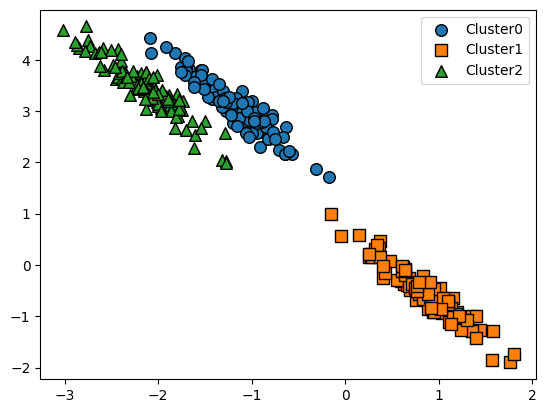

In [ ]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples = 300, n_features = 2, centers = 3,
                  cluster_std = 0.5, random_state = 0)
transformation = [[0.6083459, -0.63667341], [-0.40887718, 0.85253229]]
X_aniso = np.dot(X, transformation)
df = pd.DataFrame(data = X_aniso, columns = ["ftr1", "ftr2"])
df["target"] = y

visualize_cluster_plot(None, df, "target", iscenter = False)